# GSS 2018: synthpop versus LSM marginal distributions

Run cells in order with `gss_2018.csv` beside this notebook. Both generators fit the **same rows and variables**, and produce the same number of samples. By default this is an in-sample marginal fidelity comparison. Set `TRAIN_FRACTION = 0.5` for a shared training/holdout split. Frequencies are unweighted; exclude survey weights and identifiers explicitly if appropriate.

All columns are treated as **categorical survey codes**, including numeric-looking codes. Blank fields are a separate missing category; values such as NA, DK or refusal codes are preserved literally. This is unsuitable for continuous variables without discretization. Good marginals do not establish good joint/conditional structure or privacy.

Requirements: Python with pandas, numpy, matplotlib, nbformat, rpy2, lsynth and quasinet; R with synthpop. On MCC, select your existing Python environment as the kernel and load/configure R **before launching Jupyter**. Run expensive fits on an allocated compute node. No qmodel is required for synthpop or for these marginal metrics.

Source: https://github.com/zeroknowledgediscovery/lsynth (LSM uses `generate_syndata` and QuasiNet).

In [1]:
# Optional installation: uncomment only if needed, then restart the kernel.
# %pip install pandas numpy matplotlib rpy2 lsynth quasinet
# Or, from the lsynth repository: %pip install -e .
# R installation (run in an R terminal):
# install.packages("synthpop", repos="https://cloud.r-project.org")

In [2]:
import os
from pathlib import Path

r_home = (
    "/mnt/gpfs3_amd/share/apps/spack/0.16.2-3602-af806a8c1e/"
    "opt/spack/linux-centos8-zen2/gcc-9.3.0/"
    "r-4.4.0-7nl5q44zyluy2hclomwuoiq2jbkfsqrt/rlib/R"
)

os.environ["R_HOME"] = r_home
os.environ["PATH"] = f"{r_home}/bin" + os.pathsep + os.environ["PATH"]

import rpy2.robjects as ro

r_library = "/project/ich248_uksr/HD/R-library/4.4"
ro.r[".libPaths"](
    ro.StrVector([r_library] + list(ro.r[".libPaths"]()))
)

print(ro.r["R.version.string"][0])
print(
    "synthpop installed:",
    bool(ro.r["requireNamespace"]("synthpop", quietly=True)[0]),
)

R version 4.4.0 (2024-04-24)
synthpop installed: True


In [17]:
from pathlib import Path
import json, time, random, hashlib, inspect
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path("gss_2018.csv")
OUT_DIR = Path("gss_2018_marginal_results")
N_SYNTH = 1000
SEED = 123
TRAIN_FRACTION = 1.0  # 0.5 = half for training, half for evaluation
N_WORKERS = 2
DROP_COLUMNS = []  # e.g. respondent ID and survey weight columns
MAX_LEVELS_EXCLUSIVE = 20  # keep only columns with strictly fewer than 20 levels
LSM_CSV = None  # Path("existing_lsm_gss_2018.csv") to skip LSM training
PLOT_COLUMNS = []  # empty = select 6 variables with largest synthpop-vs-LSM TV
MAX_PLOT_LEVELS = 5
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert 0 < TRAIN_FRACTION <= 1 and N_SYNTH > 0
random.seed(SEED)
np.random.seed(SEED)

## Load and encode consistently
Before splitting or fitting, keep only columns with **fewer than 20 distinct values** in the full input data (after explicit column drops). Empty strings count as a level, so a column with exactly 20 levels is excluded. The same filtered columns are used by both models and all marginal comparisons. This full-data schema filter also applies when using a holdout.

Short tokens prevent string truncation during lsynth sampling. The same reversible mapping is used for both models. Constant columns are restored after synthesis. Review the column inventory before proceeding.

In [18]:
real = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False).drop(columns=DROP_COLUMNS)
assert len(real) >= 2 and real.shape[1] > 0
assert real.columns.is_unique
# Whitespace is intentionally preserved; only genuinely empty CSV fields mean missing.
inventory = pd.DataFrame({"levels": real.nunique(), "blank_fraction": real.eq("").mean()})
inventory["retained"] = inventory["levels"] < MAX_LEVELS_EXCLUSIVE
display(inventory)
inventory.to_csv(OUT_DIR / "column_inventory.csv")
excluded_columns = inventory.index[~inventory["retained"]].tolist()
print("Excluded columns (20 or more levels):", excluded_columns)
real = real.loc[:, inventory.index[inventory["retained"]]].copy()
if real.shape[1] == 0:
    raise ValueError("No columns have fewer than 20 levels")
print("Filtered data shape:", real.shape)
order = np.random.default_rng(SEED).permutation(len(real))
n_train = len(real) if TRAIN_FRACTION == 1 else int(len(real) * TRAIN_FRACTION)
assert n_train >= 2 and (TRAIN_FRACTION == 1 or n_train < len(real))
train = real.iloc[order[:n_train]].reset_index(drop=True)
reference = real if TRAIN_FRACTION == 1 else real.iloc[order[n_train:]].reset_index(drop=True)
reference_label = "original" if TRAIN_FRACTION == 1 else "holdout"
constants = {col: train[col].iloc[0] for col in train if train[col].nunique() == 1}
active = [col for col in train if col not in constants]
encoders = {col: {value: f"v{i}" for i, value in enumerate(pd.unique(train[col]))} for col in active}
decoders = {col: {token: value for value, token in mapping.items()} for col, mapping in encoders.items()}
encoded = pd.DataFrame({col: train[col].map(encoders[col]) for col in active})
print(f"Training: {len(train)}; reference: {len(reference)}; active: {len(active)}; constant: {len(constants)}")
train.to_csv(OUT_DIR / "training_data.csv", index=False)
reference.to_csv(OUT_DIR / "reference_data.csv", index=False)
with open(OUT_DIR / "encoding.json", "w") as f:
    json.dump({"encoders": encoders, "constants": constants}, f, indent=2)

def decode_generated(df):
    if list(df.columns) != active:
        raise ValueError(
            "Generated columns/order do not match training features"
        )

    decoded = {}

    for col in active:
        values = df[col].astype(str).reset_index(drop=True)
        unknown = set(values) - set(decoders[col])

        if unknown:
            raise ValueError(
                f"Unknown generated tokens in {col}: {list(unknown)[:5]}"
            )

        decoded[col] = values.map(decoders[col])

    for col, value in constants.items():
        decoded[col] = pd.Series(value, index=range(len(df)))

    return pd.DataFrame(decoded, index=range(len(df))).loc[:, real.columns]

timings = {}

,levels,blank_fraction,retained
wrkstat,9,0.001121,True
HRS1,5,0.000000,True
HRS2,4,0.000000,True
evwork,3,0.670404,True
wrkslf,3,0.035874,True
...,...,...,...
wtss,3,0.000000,True
wtssnr,4,0.000000,True
wtssall,3,0.000000,True
vstrat,78,0.000000,False


Excluded columns (20 or more levels): ['SPIND10', 'COIND10', 'MAIND10', 'MAJOR1', 'MAJOR2', 'INCOME16', 'RINCOM16', 'size', 'denom', 'other', 'DENOM16', 'OTH16', 'spden', 'spother', 'OTHLANG1', 'OTHLANG2', 'majorcol', 'madenkid', 'padenkid', 'denkid', 'ethnic', 'ETH1', 'ETH2', 'ETH3', 'hhtype', 'RELHH3', 'dateintv', 'ISCO08', 'PAISCO08', 'MAISCO08', 'SPISCO08', 'COISCO08', 'intid', 'lngthinv', 'intage', 'intyrs', 'sampcode', 'vstrat']
Filtered data shape: (1784, 996)
Training: 1784; reference: 1784; active: 996; constant: 0


In [19]:
print("Kernel responds")

Kernel responds


## Fit and generate with R synthpop
Every active variable is an R factor. CART synthesizes subsequent variables; the first is sampled. The R object is saved for inspection/reuse. A large level count can increase memory and runtime.

In [ ]:
if active:
    import rpy2.robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter
    if not bool(ro.r["requireNamespace"]("synthpop", quietly=True)[0]):
        raise RuntimeError("Install R synthpop first: install.packages('synthpop', repos='https://cloud.r-project.org')")
    with localconverter(ro.default_converter + pandas2ri.converter):
        r_data = ro.conversion.py2rpy(encoded)
    synthesize = ro.r('''function(d, k, seed, outfile) {
        d[] <- lapply(d, factor)
        fit <- synthpop::syn(d, m=1, k=as.integer(k), seed=as.integer(seed),
                            method="cart", maxfaclevels=max(60L, max(vapply(d, nlevels, integer(1)))),
                            print.flag=FALSE)
        saveRDS(fit, outfile)
        result <- as.data.frame(lapply(fit$syn, as.character), check.names=FALSE)
        names(result) <- names(d)
        result
    }''')
    started = time.perf_counter()
    r_syn = synthesize(r_data, N_SYNTH, SEED, str((OUT_DIR / "synthpop_fit.rds").resolve()))
    timings["synthpop_fit_and_generate_seconds"] = time.perf_counter() - started
    with localconverter(ro.default_converter + pandas2ri.converter):
        syn_encoded = ro.conversion.rpy2py(r_syn)
    synthpop_df = decode_generated(syn_encoded)
else:
    synthpop_df = pd.DataFrame([constants] * N_SYNTH).loc[:, real.columns]
assert len(synthpop_df) == N_SYNTH
synthpop_df.to_csv(OUT_DIR / "synthpop_generated.csv", index=False)
print("synthpop:", synthpop_df.shape, timings)

## Fit and generate with LSM in lsynth
Default: train a fresh QuasiNet on exactly the synthpop training data. An existing LSM CSV must contain decoded original values and exactly the same filtered columns; you must verify that it used the same training cohort/preprocessing. Its first `N_SYNTH` rows are used, so supply at least that many. LSM threaded sampling may not be fully reproducible across environments.

In [21]:
from pathlib import Path
from quasinet.qnet import load_qnet
from lsynth import generate_syndata

MODEL_PATH = Path("gss_2018.joblib")

model = load_qnet(str(MODEL_PATH))
model_columns = list(model.feature_names)

missing = [col for col in real.columns if col not in model_columns]
if missing:
    raise ValueError(
        f"Saved model is missing comparison columns: {missing}"
    )

np.random.seed(SEED)
started = time.perf_counter()

lsm_generated = generate_syndata(
    num=N_SYNTH,
    model=model,
    feature_names=model_columns,
    gen_algorithm="LSM",
    n_workers=N_WORKERS,
)

timings["lsm_generation_seconds"] = time.perf_counter() - started

# Select the same filtered columns used in the marginal comparisons.
lsm_df = (
    lsm_generated.loc[:, real.columns]
    .astype(str)
    .reset_index(drop=True)
)

assert len(lsm_df) == N_SYNTH

lsm_df.to_csv(OUT_DIR / "lsm_generated.csv", index=False)
print("LSM:", lsm_df.shape, timings)

Generating 1000 rows via LSM (qsample).


qsample(LSM, threads=2): 100%|██████████| 1000/1000 [02:16<00:00,  7.32it/s]


LSM: (1000, 996) {'synthpop_fit_and_generate_seconds': 2853.515383463353, 'lsm_generation_seconds': 137.38319885684177}


## Compare every marginal
Total variation (TV) = half the sum of absolute differences in category probabilities. It ranges from 0 (identical) to 1 (disjoint). The union of categories from all datasets is included; empty strings count as a category. We report both synthetic-vs-reference distances and the direct synthpop-vs-LSM distance. Each variable has equal weight in summary averages. These are empirical estimates from a single run, not significance tests.

In [22]:
def marginal_table(col):
    frames = {"reference": reference, "synthpop": synthpop_df, "lsm": lsm_df}
    levels = sorted(set().union(*(set(df[col]) for df in frames.values())))
    return pd.DataFrame({name: df[col].value_counts(normalize=True).reindex(levels, fill_value=0)
                         for name, df in frames.items()}).rename_axis("category")

def total_variation(p, q):
    return float(0.5 * np.abs(p - q).sum())

rows, long_tables = [], []
for col in real:
    tab = marginal_table(col)
    rows.append({"variable": col, "levels": len(tab),
                 "synthpop_vs_reference_tv": total_variation(tab.synthpop, tab.reference),
                 "lsm_vs_reference_tv": total_variation(tab.lsm, tab.reference),
                 "synthpop_vs_lsm_tv": total_variation(tab.synthpop, tab.lsm)})
    long_tables.append(tab.reset_index().assign(variable=col))
scores = pd.DataFrame(rows).set_index("variable")
scores["synthpop_minus_lsm_reference_tv"] = scores.synthpop_vs_reference_tv - scores.lsm_vs_reference_tv
scores = scores.sort_values("synthpop_vs_lsm_tv", ascending=False)
marginals = pd.concat(long_tables, ignore_index=True)[["variable", "category", "reference", "synthpop", "lsm"]]
scores.to_csv(OUT_DIR / "marginal_distances.csv")
marginals.to_csv(OUT_DIR / "marginal_probabilities.csv", index=False)
display(scores.head(20))
display(scores.filter(like="_tv").agg(["mean", "median", "max"]))

,levels,synthpop_vs_reference_tv,lsm_vs_reference_tv,synthpop_vs_lsm_tv,synthpop_minus_lsm_reference_tv
variable,,,,,
RELATE8,3,0.001682,0.665637,0.667,-0.663955
RELHHD8,3,0.001682,0.659637,0.661,-0.657955
lasers,5,0.032166,0.660000,0.660,-0.627834
boyorgrl,5,0.007368,0.655000,0.655,-0.647632
MCSDS7,5,0.022816,0.654000,0.654,-0.631184
WHERE1,4,0.001318,0.651274,0.651,-0.649955
MCSDS6,5,0.015731,0.648000,0.648,-0.632269
RELATE11,6,0.002484,0.645668,0.647,-0.643184
MCSDS4,5,0.010417,0.646000,0.646,-0.635583


,synthpop_vs_reference_tv,lsm_vs_reference_tv,synthpop_vs_lsm_tv,synthpop_minus_lsm_reference_tv
mean,0.018531,0.270886,0.273372,-0.252355
median,0.018049,0.287489,0.293000,-0.264363
max,0.082309,0.665637,0.667000,0.029000


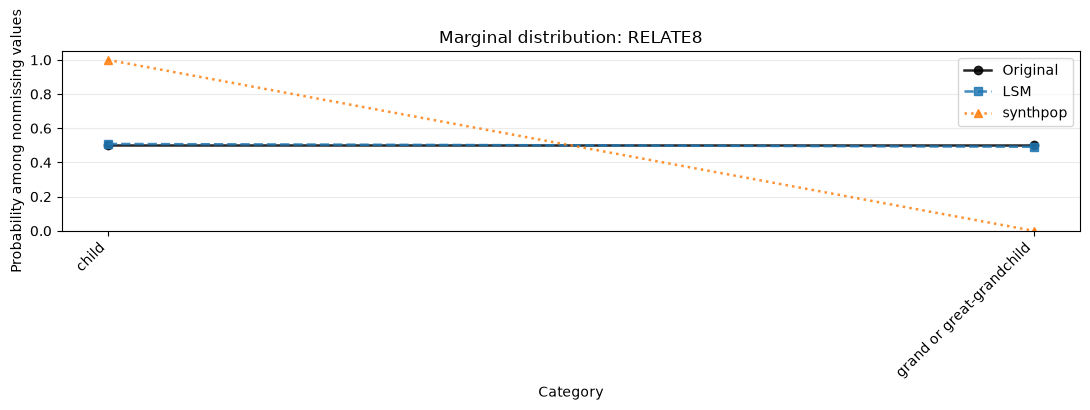

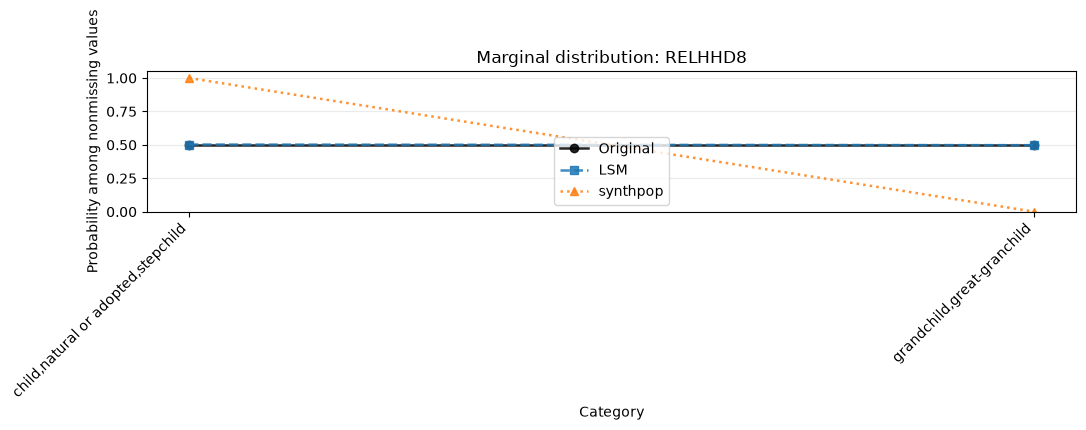

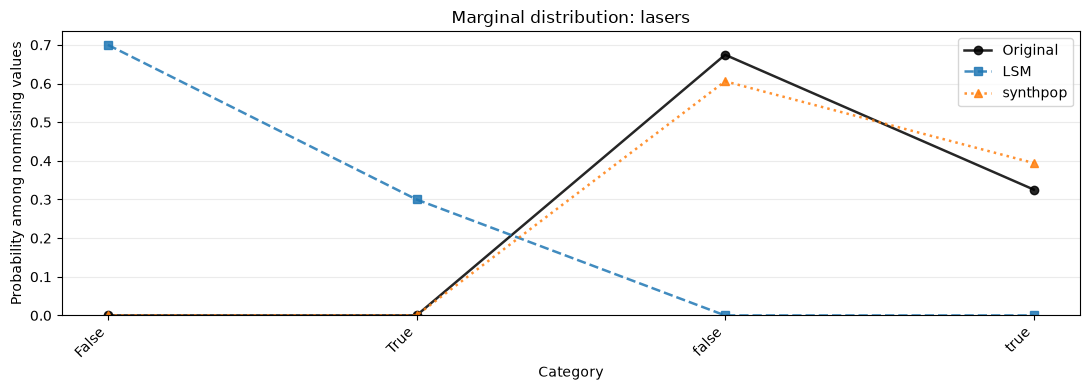

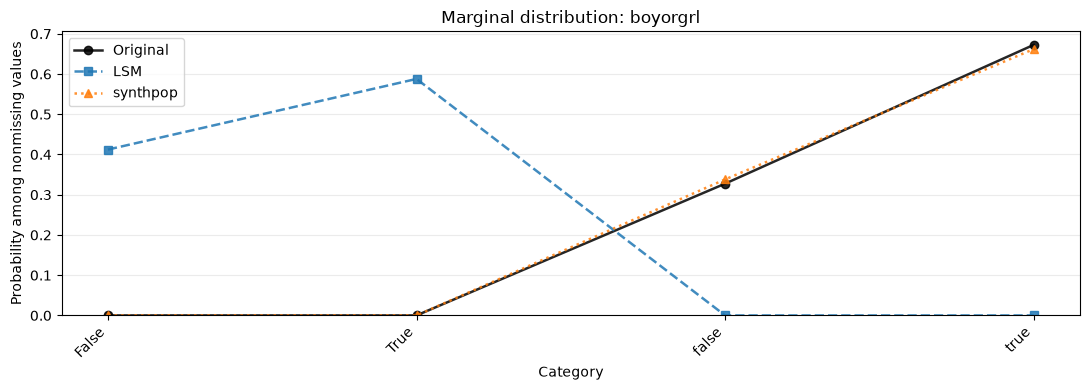

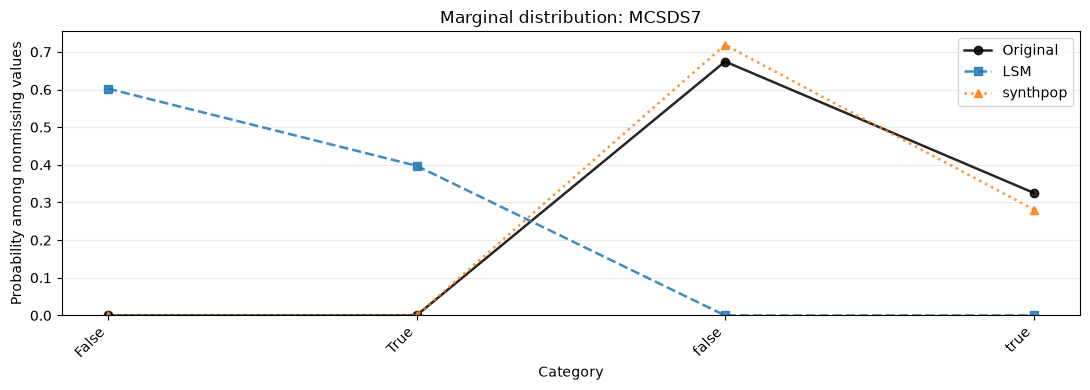

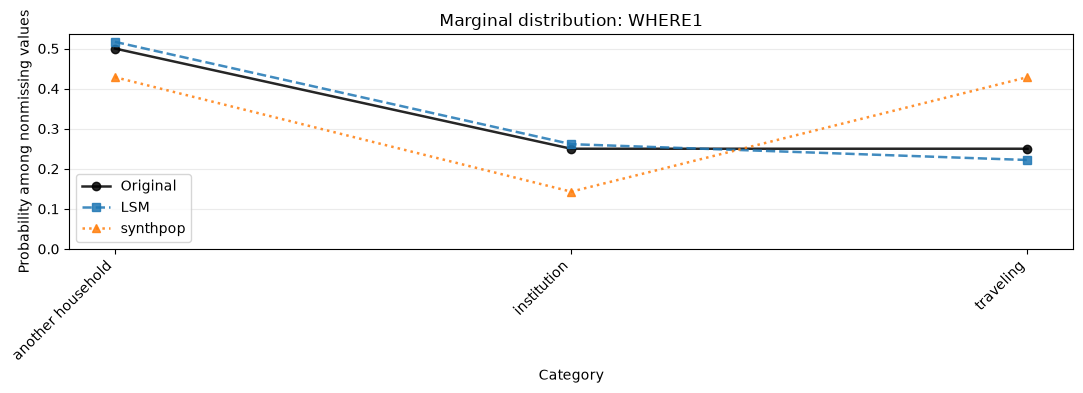

In [23]:
import numpy as np
import matplotlib.pyplot as plt

plot_cols = PLOT_COLUMNS or scores.head(6).index.tolist()

for i, col in enumerate(plot_cols):
    datasets = {
        "Original": real,
        "LSM": lsm_df,
        "synthpop": synthpop_df,
    }

    cleaned = {}
    for name, df in datasets.items():
        values = df[col].dropna().astype(str)
        cleaned[name] = values[values.str.strip().ne("")]

    levels = set().union(*(set(values) for values in cleaned.values()))
    if not levels:
        continue

    def category_order(value):
        try:
            return (0, float(value), value)
        except ValueError:
            return (1, 0, value)

    levels = sorted(levels, key=category_order)
    x = np.arange(len(levels))

    fig, ax = plt.subplots(figsize=(11, 4))

    styles = {
        "Original": ("black", "o", "-"),
        "LSM": ("tab:blue", "s", "--"),
        "synthpop": ("tab:orange", "^", ":"),
    }

    for name, values in cleaned.items():
        if values.empty:
            continue

        probabilities = (
            values.value_counts(normalize=True)
            .reindex(levels, fill_value=0)
        )

        color, marker, linestyle = styles[name]
        ax.plot(
            x,
            probabilities.to_numpy(),
            label=name,
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=1.8,
            markersize=6,
            alpha=0.85,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(levels, rotation=45, ha="right")
    ax.set(
        title=f"Marginal distribution: {col}",
        xlabel="Category",
        ylabel="Probability among nonmissing values",
    )
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

    fig.tight_layout()
    fig.savefig(OUT_DIR / f"marginal_lines_{i + 1:02d}.png", dpi=160)
    plt.show()

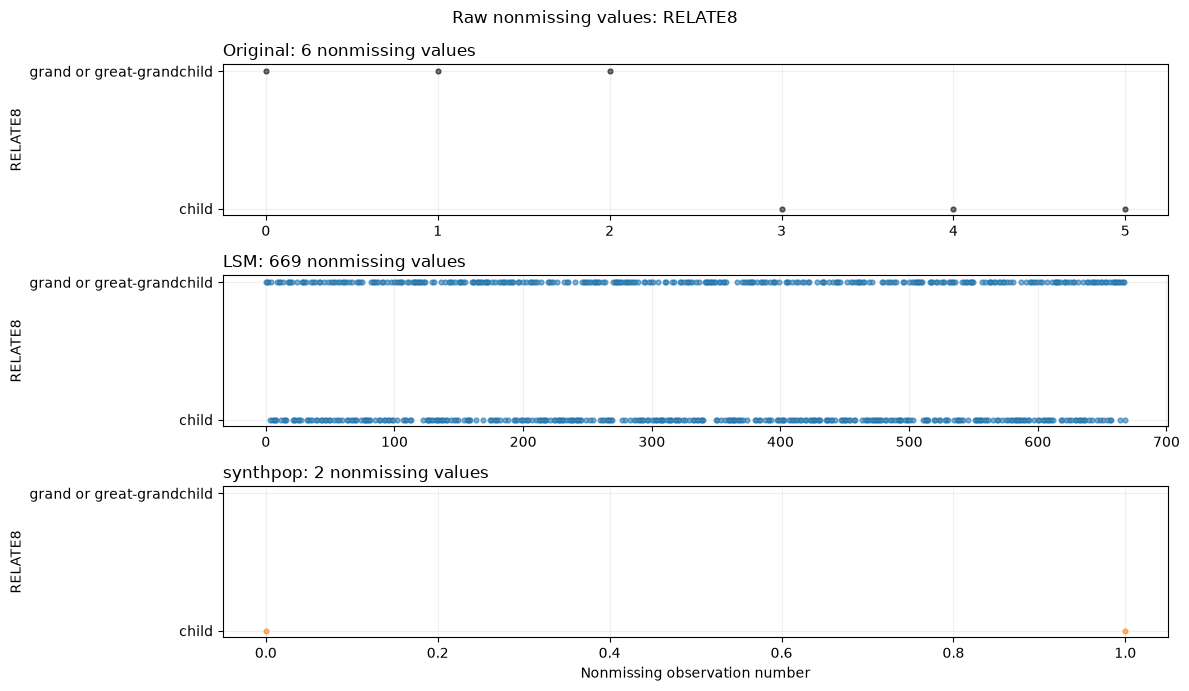

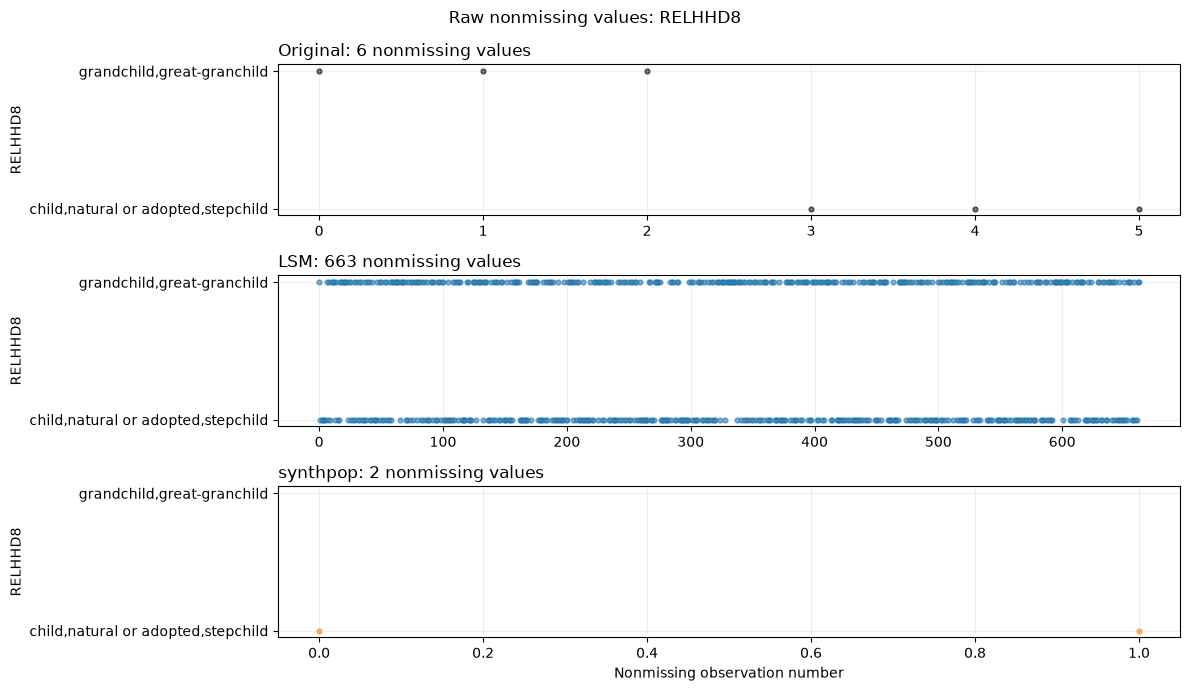

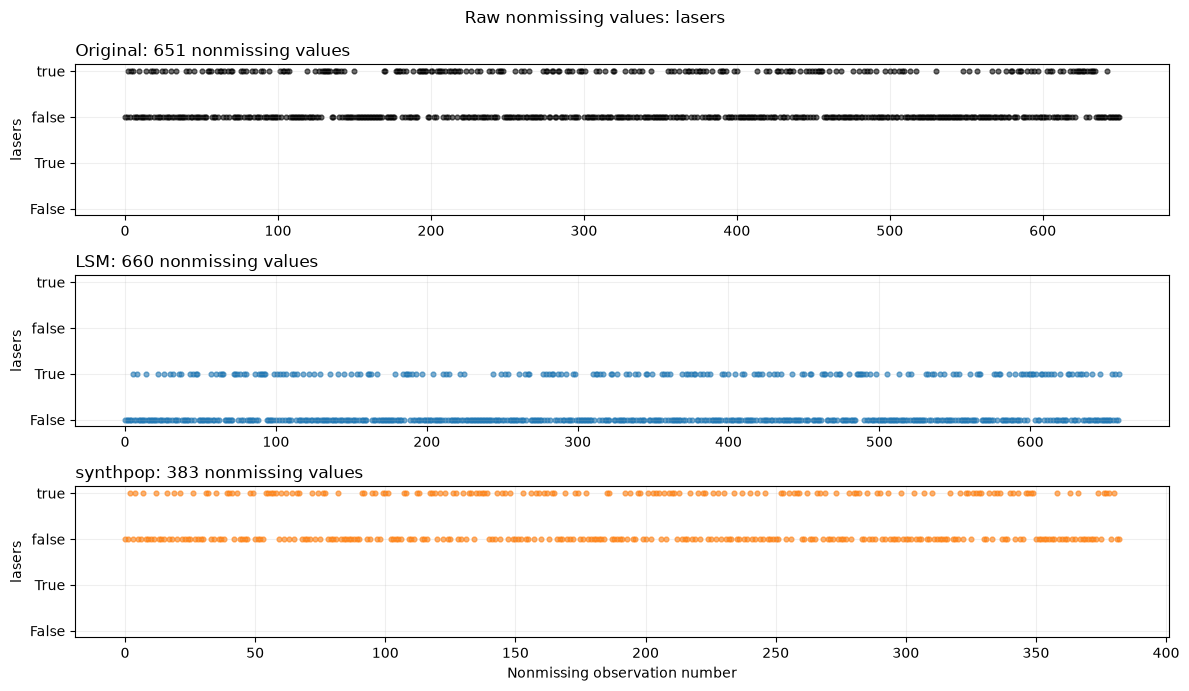

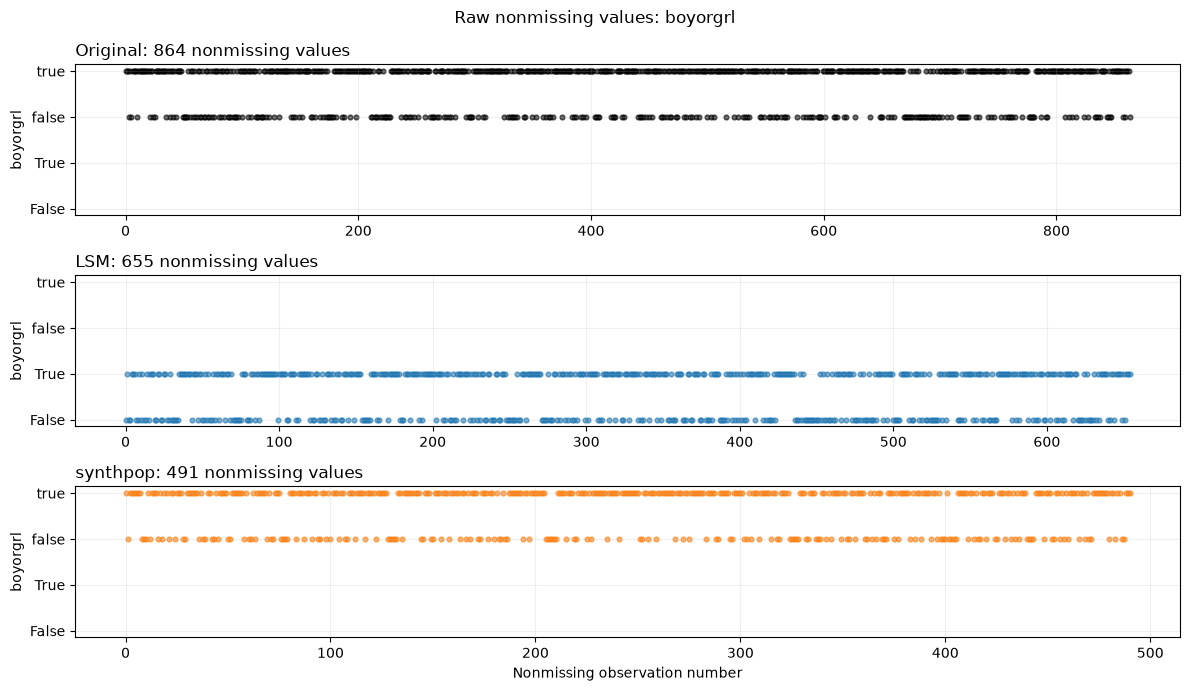

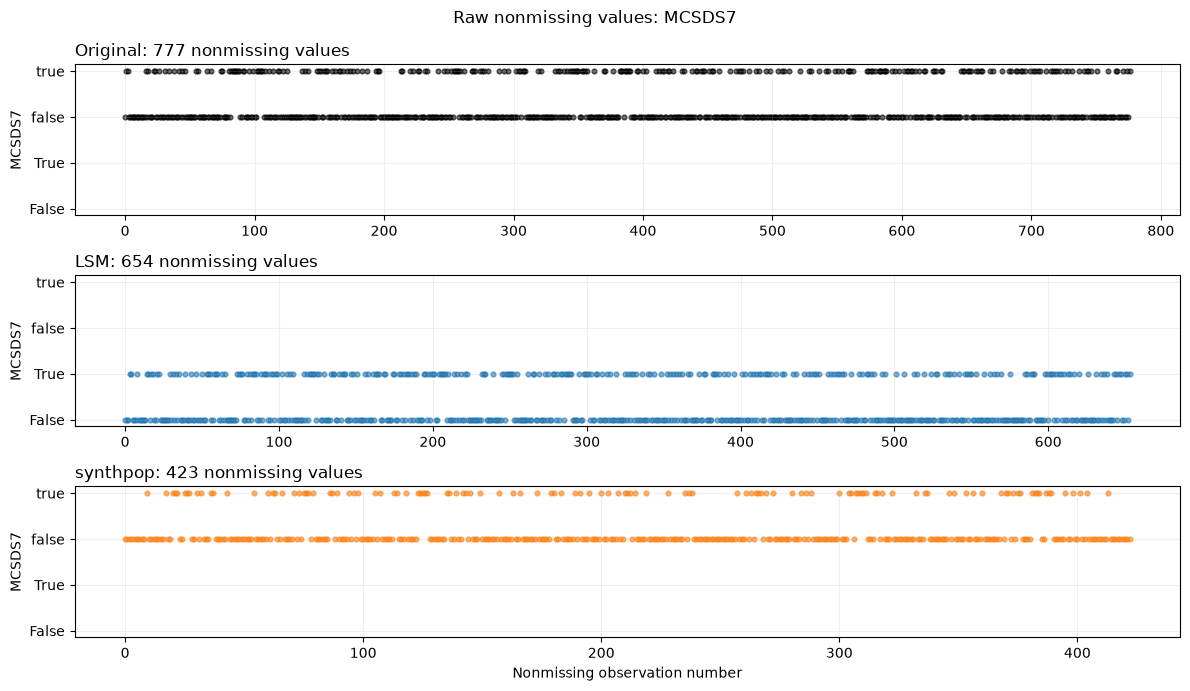

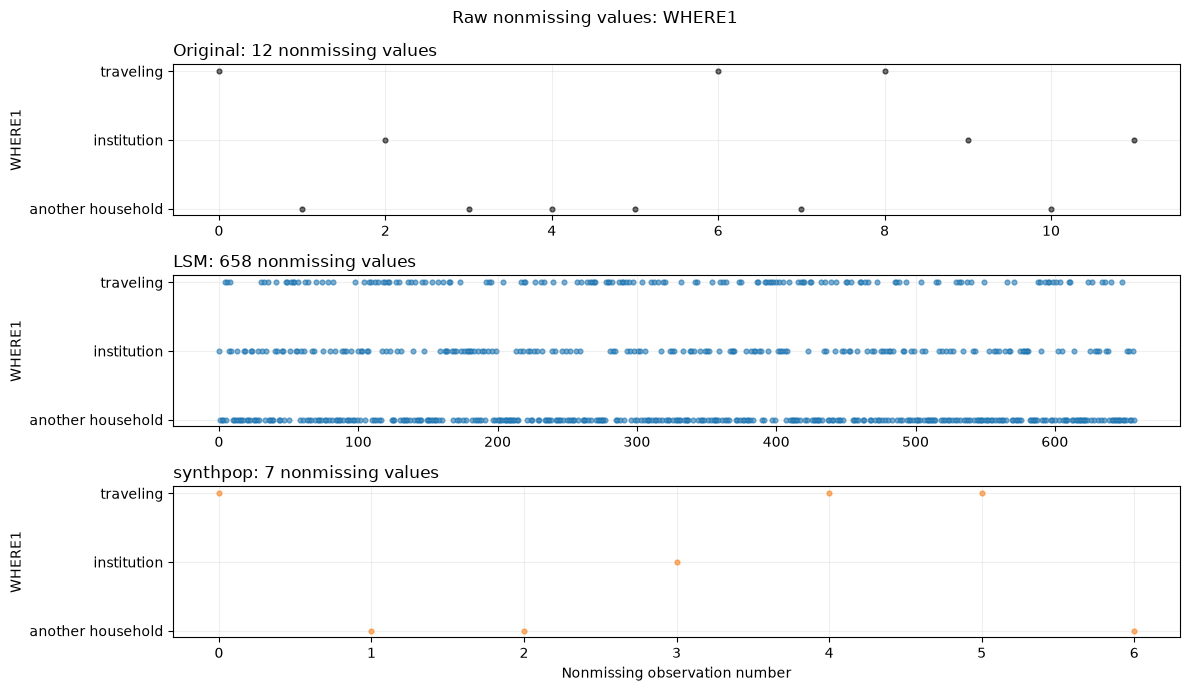

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

MISSING_LABELS = {"", "nan", "na", "n/a", "none", "null", "<na>"}
plot_cols = PLOT_COLUMNS or scores.head(6).index.tolist()

for i, col in enumerate(plot_cols):
    cleaned = {}

    for name, df in {
        "Original": real,
        "LSM": lsm_df,
        "synthpop": synthpop_df,
    }.items():
        values = df[col].dropna().astype(str).str.strip()
        cleaned[name] = values[
            ~values.str.lower().isin(MISSING_LABELS)
        ].reset_index(drop=True)

    combined = pd.concat(cleaned.values(), ignore_index=True)
    if combined.empty:
        continue

    numeric = pd.to_numeric(combined, errors="coerce").notna().all()

    if not numeric:
        levels = sorted(combined.unique())
        mapping = {value: j for j, value in enumerate(levels)}

    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharey=True)

    for ax, (name, values), color in zip(
        axes, cleaned.items(), ["black", "tab:blue", "tab:orange"]
    ):
        y = pd.to_numeric(values) if numeric else values.map(mapping)

        ax.scatter(range(len(y)), y, s=12, alpha=0.6, color=color)
        ax.set_title(f"{name}: {len(values)} nonmissing values", loc="left")
        ax.set_ylabel(col)
        ax.grid(alpha=0.2)

        if values.empty:
            ax.text(
                0.5, 0.5, "No nonmissing values",
                transform=ax.transAxes, ha="center",
            )

    if not numeric:
        axes[0].set_yticks(range(len(levels)))
        axes[0].set_yticklabels(levels)

    axes[-1].set_xlabel("Nonmissing observation number")
    fig.suptitle(f"Raw nonmissing values: {col}")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"nonmissing_values_{i + 1:02d}.png", dpi=160)
    plt.show()

In [25]:
print("Columns used in comparisons:", real.shape[1])
print("Columns modeled by synthpop:", len(active))
print("Constant columns restored:", len(constants))
print("Columns in LSM comparison data:", lsm_df.shape[1])
print("Columns in synthpop generated data:", synthpop_df.shape[1])
print("Columns currently plotted:", len(plot_cols))

Columns used in comparisons: 996
Columns modeled by synthpop: 996
Constant columns restored: 0
Columns in LSM comparison data: 996
Columns in synthpop generated data: 996
Columns currently plotted: 6


In [11]:
versions = {}
for package in ["pandas", "numpy", "rpy2", "lsynth", "quasinet"]:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "not installed"
report = {"data_path": str(DATA_PATH), "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
          "seed": SEED, "train_fraction": TRAIN_FRACTION, "training_rows": len(train),
          "reference_rows": len(reference), "generated_rows_per_model": N_SYNTH,
          "variables": real.shape[1], "drop_columns": DROP_COLUMNS,
          "max_levels_exclusive": MAX_LEVELS_EXCLUSIVE, "excluded_level_columns": excluded_columns,
          "lsm_csv": str(LSM_CSV) if LSM_CSV is not None else None,
          "timings": timings, "versions": versions,
          "mean_tv": scores.filter(like="_tv").mean().to_dict()}
with open(OUT_DIR / "run_summary.json", "w") as f:
    json.dump(report, f, indent=2)
print("Results saved to:", OUT_DIR.resolve())

Results saved to: /project/ich248_uksr/HD/lsynth/synth_comp/gss_2018_marginal_results


### Reading the results
Lower synthetic-vs-reference TV means closer marginal fidelity. Points above the diagonal have lower TV for LSM; below it, lower TV for synthpop. The direct synthpop-vs-LSM distance measures disagreement, not which model is more faithful. Full per-category probabilities are saved for every column, even when plots group levels. Repeat across seeds and use a shared holdout for a stronger benchmark. With a holdout, categories absent from training can appear in the reference and will contribute to the distance.